<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta5_g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


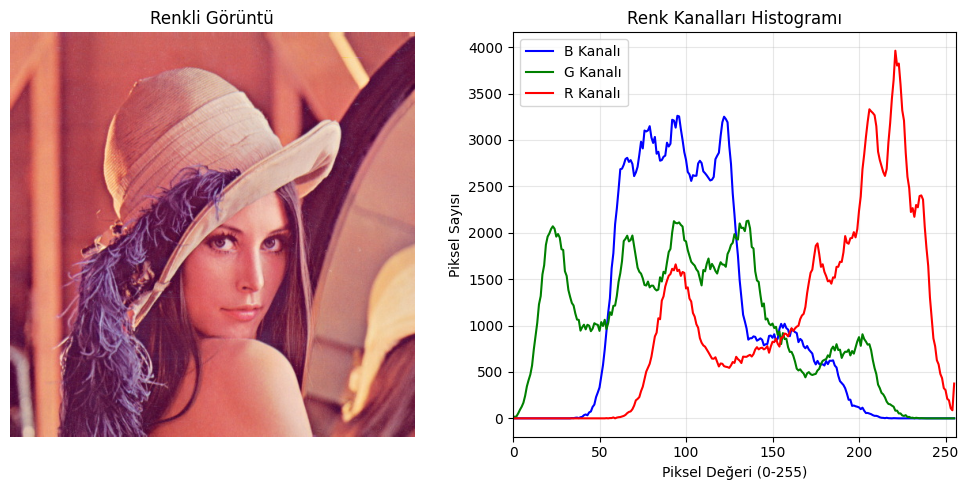

In [ ]:
import cv2
import matplotlib.pyplot as plt
import urllib.request
import numpy as np

# 1. Erişim engeli olmayan alternatif bir bağlantı (GitHub ham görsel linki)
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

# 2. Kanalları Ayırma (BGR)
color = ('b', 'g', 'r')
channels = cv2.split(img)

# 3. Histogramları Çizdirme
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Renkli Görüntü')
plt.axis('off')

plt.subplot(1, 2, 2)
for channel, col in zip(channels, color):
    hist = cv2.calcHist([channel], [0], None, [256], [0, 256])
    plt.plot(hist, color=col, label=f'{col.upper()} Kanalı')
    plt.xlim([0, 256])

plt.title('Renk Kanalları Histogramı')
plt.xlabel('Piksel Değeri (0-255)')
plt.ylabel('Piksel Sayısı')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()